In [2]:
import numpy as np
import pandas as pd

In [3]:
transaction_df = pd.read_csv("train_transaction.csv")

In [4]:
transaction_df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
transaction_df.shape

(590540, 394)

This dataset contains online e-commerce card transactions in which fraud has occurred

In [6]:
transaction_df.isnull().sum()

TransactionID          0
isFraud                0
TransactionDT          0
TransactionAmt         0
ProductCD              0
                   ...  
V335              508189
V336              508189
V337              508189
V338              508189
V339              508189
Length: 394, dtype: int64

In [7]:
transaction_df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
590535    False
590536    False
590537    False
590538    False
590539    False
Length: 590540, dtype: bool

In [8]:
#fraud distribution
transaction_df["isFraud"].value_counts()

isFraud
0    569877
1     20663
Name: count, dtype: int64

In [9]:
transaction_df["isFraud"].value_counts(normalize=True) * 100

isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

Fraud datasets are usually highly imbalanced

In [10]:
transaction_df.dtypes.value_counts()

float64    376
object      14
int64        4
Name: count, dtype: int64

In [11]:
missing = transaction_df.isnull().sum().sort_values(ascending=False)
missing.head(20)

dist2    552913
D7       551623
D13      528588
D14      528353
D12      525823
D6       517353
D9       515614
D8       515614
V153     508595
V139     508595
V162     508595
V161     508595
V154     508595
V138     508595
V158     508595
V157     508595
V163     508595
V156     508595
V155     508595
V149     508595
dtype: int64

In [12]:
transaction_df[["TransactionAmt", "TransactionDT"]].describe()

,TransactionAmt,TransactionDT
count,590540.000000,5.905400e+05
mean,135.027176,7.372311e+06
std,239.162522,4.617224e+06
min,0.251000,8.640000e+04
25%,43.321000,3.027058e+06
50%,68.769000,7.306528e+06
75%,125.000000,1.124662e+07
max,31937.391000,1.581113e+07


In [13]:
transaction_df.groupby("ProductCD")["isFraud"].agg(["count", "sum", "mean"]).sort_values("mean", ascending=False)

,count,sum,mean
ProductCD,,,
C,68519,8008,0.116873
S,11628,686,0.058996
H,33024,1574,0.047662
R,37699,1426,0.037826
W,439670,8969,0.020399


In [14]:
transaction_df.groupby("ProductCD")["isFraud"].mean() * 100

ProductCD
C    11.687269
H     4.766231
R     3.782594
S     5.899553
W     2.039939
Name: isFraud, dtype: float64

Fraud percentage for each product category

In [15]:
transaction_df.groupby("isFraud")["TransactionAmt"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,134.511665,239.395078,0.251,43.970,68.5,120.0,31937.391
1,20663.0,149.244779,232.212163,0.292,35.044,75.0,161.0,5191.000


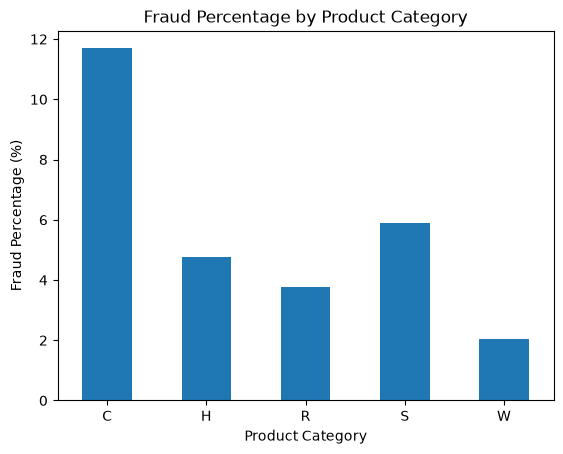

In [16]:
import matplotlib.pyplot as plt

fraud_by_product = (
    transaction_df.groupby("ProductCD")["isFraud"].mean() * 100
)
fraud_by_product.plot(kind="bar")

plt.title("Fraud Percentage by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Fraud Percentage (%)")
plt.xticks(rotation=0)
plt.show()

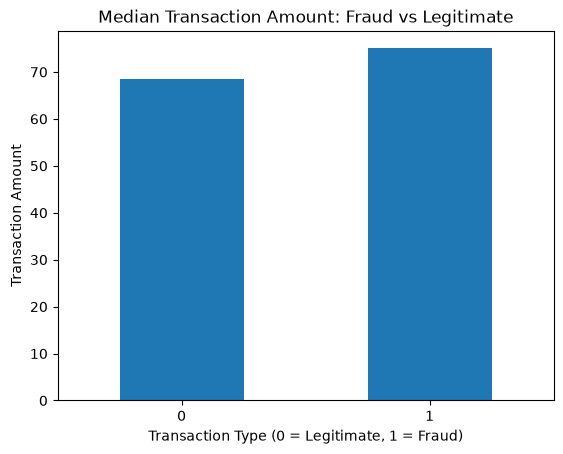

In [17]:
transaction_df.groupby("isFraud")["TransactionAmt"].median().plot(kind="bar")
plt.title("Median Transaction Amount: Fraud vs Legitimate")
plt.xlabel("Transaction Type (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.xticks(rotation=0)
plt.show()

In [18]:
#missing values in each column
missing_percent = (transaction_df.isnull().mean() * 100).sort_values(ascending=False)
missing_percent.head(30)

dist2    93.628374
D7       93.409930
D13      89.509263
D14      89.469469
D12      89.041047
D6       87.606767
D9       87.312290
D8       87.312290
V153     86.123717
V139     86.123717
V162     86.123717
V161     86.123717
V154     86.123717
V138     86.123717
V158     86.123717
V157     86.123717
V163     86.123717
V156     86.123717
V155     86.123717
V149     86.123717
V148     86.123717
V147     86.123717
V146     86.123717
V142     86.123717
V141     86.123717
V140     86.123717
V151     86.122701
V152     86.122701
V145     86.122701
V144     86.122701
dtype: float64

In [19]:
missing_percent.describe()

count    394.000000
mean      41.073431
std       35.895976
min        0.000000
25%        0.214888
50%       28.612626
75%       77.913435
max       93.628374
dtype: float64

So a large portion of the dataset has substantial missing data

In [20]:
bins = [0, 10, 30, 50, 70, 90, 100]
labels = [
    "0-10%",
    "10-30%",
    "30-50%",
    "50-70%",
    "70-90%",
    "90-100%"
]
missing_groups = pd.cut(
    missing_percent,
    bins=bins,
    labels=labels,
    include_lowest=True
)
missing_groups.value_counts().sort_index()

0-10%      112
10-30%      90
30-50%      18
50-70%       6
70-90%     166
90-100%      2
Name: count, dtype: int64

202 out of 394 features have more than 70% missing values.

In [21]:
transaction_df.dtypes.to_frame("dtype").head(50)

,dtype
TransactionID,int64
isFraud,int64
TransactionDT,int64
TransactionAmt,float64
ProductCD,object
card1,int64
card2,float64
card3,float64
card4,object
card5,float64


In [22]:
transaction_df.select_dtypes(include="object").columns.tolist()

['ProductCD',
 'card4',
 'card6',
 'P_emaildomain',
 'R_emaildomain',
 'M1',
 'M2',
 'M3',
 'M4',
 'M5',
 'M6',
 'M7',
 'M8',
 'M9']

In [23]:
for col in transaction_df.select_dtypes(include="object").columns:
   print(col, "→", transaction_df[col].nunique(), "unique values")

ProductCD → 5 unique values
card4 → 4 unique values
card6 → 4 unique values
P_emaildomain → 59 unique values
R_emaildomain → 60 unique values
M1 → 2 unique values
M2 → 2 unique values
M3 → 2 unique values
M4 → 3 unique values
M5 → 2 unique values
M6 → 2 unique values
M7 → 2 unique values
M8 → 2 unique values
M9 → 2 unique values


In [24]:
unique_counts = transaction_df.nunique().sort_values()
unique_counts.head(30)

M5         2
V107       2
V1         2
V88        2
V65        2
V14        2
V305       2
M2         2
M1         2
M6         2
M7         2
M8         2
V41        2
M9         2
isFraud    2
M3         2
M4         3
V68        3
V89        3
V94        3
V12        4
V28        4
V27        4
card6      4
V35        4
V122       4
V121       4
V117       4
V118       4
card4      4
dtype: int64

In [25]:
#creating copy of original dataset
df = transaction_df.copy()

In [26]:
X = df.drop("isFraud", axis=1)
y = df["isFraud"]

In [27]:
#Remove TransactionID
X = X.drop("TransactionID", axis=1)

In [28]:
missing_threshold = 0.80
missing_ratio = X.isnull().mean()
cols_to_drop = missing_ratio[missing_ratio > missing_threshold].index
X = X.drop(columns=cols_to_drop)

print("Removed:", len(cols_to_drop))
print("Remaining features:", X.shape[1])

Removed: 55
Remaining features: 337


After setting up the threshold to 80% missingness => 55 columns were dropped and 337 are left to train model.

In [29]:
print(X.shape)
print(X.dtypes.value_counts())

(590540, 337)
float64    321
object      14
int64        2
Name: count, dtype: int64


In [30]:
X.isnull().sum().sum()

np.int64(67434214)

In [31]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42, stratify=y)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (472432, 337)
X_test: (118108, 337)
y_train: (472432,)
y_test: (118108,)


In [32]:
print("Training fraud distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting fraud distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

Training fraud distribution:
isFraud
0    455902
1     16530
Name: count, dtype: int64
isFraud
0    96.501084
1     3.498916
Name: proportion, dtype: float64

Testing fraud distribution:
isFraud
0    113975
1      4133
Name: count, dtype: int64
isFraud
0    96.50066
1     3.49934
Name: proportion, dtype: float64


In [33]:
# Checking object/categorical columns
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()

print("Categorical columns:")
print(categorical_cols)
print("\nNumber of categorical columns:", len(categorical_cols))

for col in categorical_cols:
    print(col, "->", X_train[col].nunique(), "unique values")

Categorical columns:
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']

Number of categorical columns: 14
ProductCD -> 5 unique values
card4 -> 4 unique values
card6 -> 4 unique values
P_emaildomain -> 59 unique values
R_emaildomain -> 60 unique values
M1 -> 2 unique values
M2 -> 2 unique values
M3 -> 2 unique values
M4 -> 3 unique values
M5 -> 2 unique values
M6 -> 2 unique values
M7 -> 2 unique values
M8 -> 2 unique values
M9 -> 2 unique values


In [34]:
# One-hot encode categorical columns

X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    dummy_na=True
)
X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    dummy_na=True
)
X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded,
    join="left",
    axis=1,
    fill_value=0
)
print("X_train encoded:", X_train_encoded.shape)
print("X_test encoded:", X_test_encoded.shape)

X_train encoded: (472432, 488)
X_test encoded: (118108, 488)


In [35]:
# Checking remaining missing values after OHE
missing_after_threshold = X_train_encoded.isnull().mean().sort_values(ascending=False) * 100
print("Top 30 columns by remaining missing percentage:")
print(missing_after_threshold.head(30))

Top 30 columns by remaining missing percentage:
V243    77.852051
V231    77.852051
V246    77.852051
V244    77.852051
V242    77.852051
V241    77.852051
V240    77.852051
V236    77.852051
V235    77.852051
V233    77.852051
V232    77.852051
V230    77.852051
V248    77.852051
V229    77.852051
V228    77.852051
V226    77.852051
V225    77.852051
V224    77.852051
V223    77.852051
V219    77.852051
V218    77.852051
V217    77.852051
V247    77.852051
V237    77.852051
V249    77.852051
V265    77.852051
V278    77.852051
V277    77.852051
V276    77.852051
V252    77.852051
dtype: float64


In [36]:
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()
print("Categorical columns:")
print(categorical_cols)
print("\nNumber of categorical columns:", len(categorical_cols))

Categorical columns:
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']

Number of categorical columns: 14


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)
print("Preprocessing pipeline created successfully.")

Numerical columns: 323
Categorical columns: 14
Preprocessing pipeline created successfully.


In [38]:
# Numerical-only baseline
numerical_features = [
    "TransactionAmt",
    "TransactionDT",
    "card1",
    "card2",
    "card3",
    "card5",
    "addr1",
    "addr2",
    "dist1",
    "dist2",
    "C1",
    "C2",
    "C3",
    "C4",
    "C5",
    "C6",
    "C7",
    "C8",
    "C9",
    "C10",
    "C11",
    "C12",
    "C13",
    "C14"
]
numerical_features = [
    col for col in numerical_features if col in X_train.columns
]
X_train_num = X_train[numerical_features].copy()
X_test_num = X_test[numerical_features].copy()
X_train_num = X_train_num.fillna(X_train_num.median())
X_test_num = X_test_num.fillna(X_train_num.median())

print("Features:", len(numerical_features))
print("Train:", X_train_num.shape)
print("Test:", X_test_num.shape)

Features: 23
Train: (472432, 23)
Test: (118108, 23)


In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
lr_model.fit(X_train_num, y_train)
print("Logistic Regression training completed.")

Logistic Regression training completed.


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [40]:
#Evaluation
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred = lr_model.predict(X_test_num)
y_prob = lr_model.predict_proba(X_test_num)[:, 1]
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))


Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.65      0.78    113975
           1       0.06      0.58      0.10      4133

    accuracy                           0.64    118108
   macro avg       0.52      0.61      0.44    118108
weighted avg       0.94      0.64      0.75    118108

ROC-AUC: 0.6563362748812555


Accuracy isn't useful by itself here because the dataset is highly imbalanced

In [41]:
#Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)
rf_model.fit(X_train_num, y_train)
print("Random Forest training completed.")

Random Forest training completed.


In [42]:
#evaluation

from sklearn.metrics import classification_report, roc_auc_score
y_pred_rf = rf_model.predict(X_test_num)
y_prob_rf = rf_model.predict_proba(X_test_num)[:, 1]

print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    113975
           1       0.88      0.69      0.78      4133

    accuracy                           0.99    118108
   macro avg       0.93      0.85      0.88    118108
weighted avg       0.99      0.99      0.99    118108

ROC-AUC: 0.9591230084022973


Random Forest is much better than Logistic Regression

In [43]:
#XGBoost baseline

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_num, y_train)
print("XGBoost training completed.")

XGBoost training completed.


In [44]:
#evaluation

from sklearn.metrics import classification_report, roc_auc_score

y_pred_xgb = xgb_model.predict(X_test_num)
y_prob_xgb = xgb_model.predict_proba(X_test_num)[:, 1]
print("XGBoost Classification Report:")
print(classification_report(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99    113975
           1       0.90      0.40      0.55      4133

    accuracy                           0.98    118108
   macro avg       0.94      0.70      0.77    118108
weighted avg       0.98      0.98      0.97    118108

ROC-AUC: 0.927589807150882


In [45]:
print("MODEL COMPARISON")
print("-----------------------------")
print("Logistic Regression ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Random Forest ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("XGBoost ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

MODEL COMPARISON
-----------------------------
Logistic Regression ROC-AUC: 0.6563362748812555
Random Forest ROC-AUC: 0.9591230084022973
XGBoost ROC-AUC: 0.927589807150882


Random Forest is the best of the three by ROC-AUC

In [46]:
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    113975
           1       0.88      0.69      0.78      4133

    accuracy                           0.99    118108
   macro avg       0.93      0.85      0.88    118108
weighted avg       0.99      0.99      0.99    118108



In [47]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_rf)
print("Random Forest Confusion Matrix:")
print(cm)

Random Forest Confusion Matrix:
[[113575    400]
 [  1262   2871]]


In [48]:
#Feature Importance

import pandas as pd
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train_num.columns
).sort_values(ascending=False)
print("Top 15 Important Features:")
print(importance.head(15))

Top 15 Important Features:
TransactionDT     0.105180
TransactionAmt    0.093111
card1             0.084625
C13               0.081041
card2             0.068685
addr1             0.062515
C5                0.059488
C14               0.048181
C1                0.044742
C2                0.039474
C8                0.037791
card5             0.037239
C6                0.032165
dist1             0.031710
C12               0.029821
dtype: float64


TransactionDT and TransactionAmt are among the strongest features, which is useful for later context/risk-factor analysis.

In [49]:
import os
print(os.getcwd())

/Users/sneha/Desktop/VeriPay


In [50]:
import pickle
with open("backend/models/ieee_cis_rf_model.pkl", "wb") as f:
    pickle.dump(rf_model, f)
print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [51]:
print(rf_model.feature_names_in_)

['TransactionAmt' 'TransactionDT' 'card1' 'card2' 'card3' 'card5' 'addr1'
 'addr2' 'dist1' 'C1' 'C2' 'C3' 'C4' 'C5' 'C6' 'C7' 'C8' 'C9' 'C10' 'C11'
 'C12' 'C13' 'C14']


In [52]:
features = rf_model.feature_names_in_
X_test_rf = X_test[features]
y_test_proba = rf_model.predict_proba(X_test_rf)[:, 1]
print(y_test_proba[:10])

[0.01 0.03 0.   0.02 0.   0.21 0.06 0.   0.   0.  ]


In [53]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_test_proba
)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
best_index = f1_scores.argmax()
print("Best threshold:", thresholds[best_index])
print("Precision:", precision[best_index])
print("Recall:", recall[best_index])
print("F1-score:", f1_scores[best_index])

Best threshold: 0.45
Precision: 0.8431760384289347
Recall: 0.7219937091700943
F1-score: 0.7778936391578075


In [54]:
from sklearn.metrics import confusion_matrix

y_test_pred_045 = (y_test_proba >= 0.45).astype(int)
cm = confusion_matrix(y_test, y_test_pred_045)
print(cm)

[[113420    555]
 [  1149   2984]]


In [55]:
tn, fp, fn, tp = cm.ravel()

fraud_detection_rate = tp / (tp + fn)
false_alarm_rate = fp / (fp + tn)
print("Fraud Detection Rate:", fraud_detection_rate)
print("False Alarm Rate:", false_alarm_rate)

Fraud Detection Rate: 0.7219937091700943
False Alarm Rate: 0.004869488923009432


In [56]:
import pandas as pd

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=rf_model.feature_names_in_
).sort_values(ascending=False)
print(feature_importance.head(10))

TransactionDT     0.105180
TransactionAmt    0.093111
card1             0.084625
C13               0.081041
card2             0.068685
addr1             0.062515
C5                0.059488
C14               0.048181
C1                0.044742
C2                0.039474
dtype: float64


In [57]:
import shap
print(shap.__version__)

0.52.0


In [58]:
import shap
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test_rf.iloc[:100])
print("SHAP values calculated successfully.")

SHAP values calculated successfully.


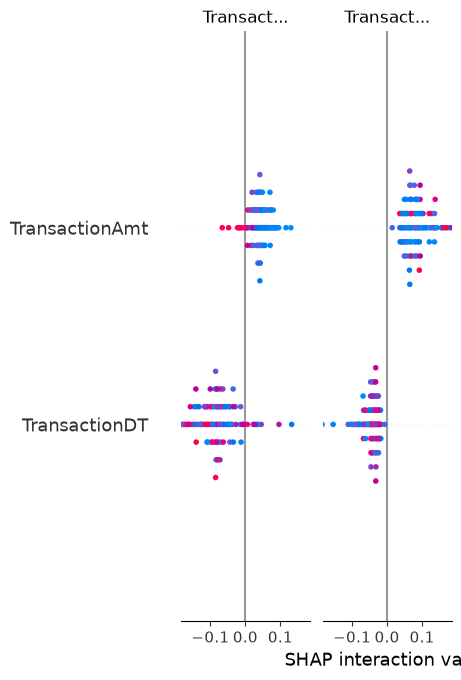

In [59]:
shap.summary_plot(
    shap_values,
    X_test_rf.iloc[:100],
    feature_names=rf_model.feature_names_in_
)

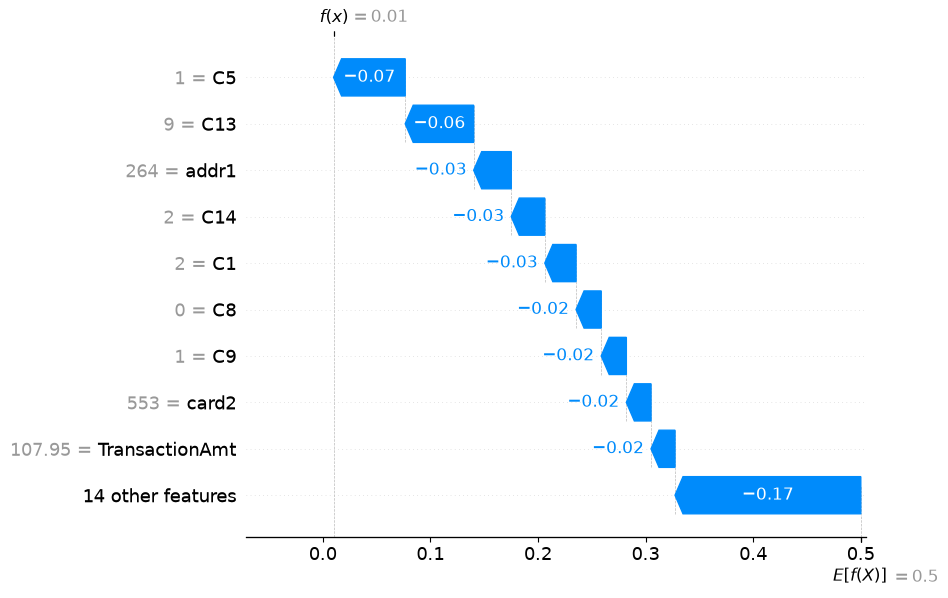

In [60]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0, :, 1],
        base_values=explainer.expected_value[1],
        data=X_test_rf.iloc[0],
        feature_names=X_test_rf.columns
    )
)

In [61]:
import numpy as np

amount_median = X_train.groupby("card1")["TransactionAmt"].median()
X_test_context = X_test_rf.copy()
X_test_context["normal_amount"] = X_test_context["card1"].map(amount_median)
X_test_context["amount_deviation"] = (
    abs(X_test_context["TransactionAmt"] - X_test_context["normal_amount"])
    / (X_test_context["normal_amount"] + 1e-6)
)
print(X_test_context[[
    "card1",
    "TransactionAmt",
    "normal_amount",
    "amount_deviation"
]].head())

        card1  TransactionAmt  normal_amount  amount_deviation
316078   7585         107.950        107.950          0.000000
116888   3154          37.021         25.535          0.449814
410211  10057          59.000         59.000          0.000000
251027   6207          57.950         54.250          0.068203
191265  11207         107.950         77.000          0.401948


In [62]:
X_test_context["transaction_velocity"] = (
    X_test_context.groupby("card1")["TransactionDT"]
    .transform("count")
)
print(X_test_context[[
    "card1",
    "TransactionDT",
    "transaction_velocity"
]].head())

        card1  TransactionDT  transaction_velocity
316078   7585        7864752                  1098
116888   3154        2260318                   924
410211  10057       10361225                   672
251027   6207        5974846                    60
191265  11207        4296816                   736


In [63]:
X_test_context = X_test_context.sort_values(
    ["card1", "TransactionDT"]
).copy()
def calculate_velocity(group):
    times = group["TransactionDT"].to_numpy()
    return np.searchsorted(times, times, side="right") - np.searchsorted(
        times, times - 86400, side="left"
    )
X_test_context["transaction_velocity"] = (
    X_test_context.groupby("card1", group_keys=False)
    .apply(calculate_velocity, include_groups=False)
    .explode()
    .astype(int)
    .values
)
print(X_test_context[[
    "card1",
    "TransactionDT",
    "transaction_velocity"
]].head(10))

        card1  TransactionDT  transaction_velocity
243924   1000        5787419                     1
41973    1004        1022173                     1
51871    1005        1212802                     1
247681   1006        5883179                     1
239241   1007        5651177                     1
550798   1008       14562384                     1
37078    1009         926293                     1
82808    1012        1784656                     1
111185   1012        2166984                     1
344616   1013        8495727                     1


In [64]:
X_test_context["context_risk"] = (
    0.6 * X_test_context["amount_deviation"]
    + 0.4 * (X_test_context["transaction_velocity"] / X_test_context["transaction_velocity"].max())
)
print(X_test_context[[
    "amount_deviation",
    "transaction_velocity",
    "context_risk"
]].head(10))

        amount_deviation  transaction_velocity  context_risk
243924               NaN                     1           NaN
41973           0.840426                     1      0.506441
51871                NaN                     1           NaN
247681          0.200000                     1      0.122186
239241          1.377451                     1      0.828656
550798          0.689775                     1      0.416051
37078           0.200000                     1      0.122186
82808           2.711098                     1      1.628845
111185          0.346413                     1      0.210033
344616          0.870033                     1      0.524205


In [65]:
global_median = X_train["TransactionAmt"].median()
X_test_context["normal_amount"] = X_test_context["normal_amount"].fillna(global_median)
X_test_context["amount_deviation"] = (
    abs(X_test_context["TransactionAmt"] - X_test_context["normal_amount"])
    / (X_test_context["normal_amount"] + 1e-6)
)
print(X_test_context[[
    "TransactionAmt",
    "normal_amount",
    "amount_deviation"
]].head(10))

        TransactionAmt  normal_amount  amount_deviation
243924          23.443         68.911          0.659808
41973           30.000        188.000          0.840426
51871           50.000         68.911          0.274426
247681         150.000        125.000          0.200000
239241          55.164         23.203          1.377451
550798          24.500         78.975          0.689775
37078          150.000        125.000          0.200000
82808          482.350        129.975          2.711098
111185         175.000        129.975          0.346413
344616         100.000         53.475          0.870033


In [66]:
print(X_test_context[[
    "amount_deviation",
    "transaction_velocity"
]].isna().sum())

amount_deviation        0
transaction_velocity    0
dtype: int64


In [67]:
amount_cap = X_test_context["amount_deviation"].quantile(0.95)
velocity_cap = X_test_context["transaction_velocity"].quantile(0.95)
amount_risk = (
    X_test_context["amount_deviation"] / amount_cap
).clip(0, 1)
velocity_risk = (
    X_test_context["transaction_velocity"] / velocity_cap
).clip(0, 1)
X_test_context["context_risk"] = (
    0.6 * amount_risk +
    0.4 * velocity_risk
)
print(X_test_context[[
    "amount_deviation",
    "transaction_velocity",
    "context_risk"
]].head(10))

        amount_deviation  transaction_velocity  context_risk
243924          0.659808                     1      0.118088
41973           0.840426                     1      0.143570
51871           0.274426                     1      0.063717
247681          0.200000                     1      0.053217
239241          1.377451                     1      0.219336
550798          0.689775                     1      0.122316
37078           0.200000                     1      0.053217
82808           2.711098                     1      0.407492
111185          0.346413                     1      0.073873
344616          0.870033                     1      0.147747


In [68]:
all_context = pd.concat([X_train, X_test]).sort_values(
    ["card1", "TransactionDT"]
).copy()

def calculate_velocity(group):
    times = group["TransactionDT"].to_numpy()   
    return np.searchsorted(
        times, times, side="left"
    ) - np.searchsorted(
        times, times - 86400, side="left"
    )
all_context["transaction_velocity"] = (
    all_context.groupby("card1", group_keys=False)
    .apply(calculate_velocity, include_groups=False)
    .explode()
    .astype(int)
    .values
)
X_test_context["transaction_velocity"] = (
    all_context.loc[X_test_context.index, "transaction_velocity"]
)
print(X_test_context[[
    "card1",
    "TransactionDT",
    "transaction_velocity"
]].head(10))

        card1  TransactionDT  transaction_velocity
243924   1000        5787419                     0
41973    1004        1022173                     0
51871    1005        1212802                     0
247681   1006        5883179                     0
239241   1007        5651177                     0
550798   1008       14562384                     0
37078    1009         926293                     0
82808    1012        1784656                     0
111185   1012        2166984                     0
344616   1013        8495727                     0


In [69]:
print(X_test_context["transaction_velocity"].describe())

count    118108.000000
mean         18.709063
std          45.649572
min           0.000000
25%           1.000000
50%           5.000000
75%          19.000000
max         880.000000
Name: transaction_velocity, dtype: float64


In [70]:
#recalculating context_risk

amount_cap = X_test_context["amount_deviation"].quantile(0.95)
velocity_cap = X_test_context["transaction_velocity"].quantile(0.95)

amount_risk = (
    X_test_context["amount_deviation"] / amount_cap
).clip(0, 1)

velocity_risk = (
    X_test_context["transaction_velocity"] / velocity_cap
).clip(0, 1)

X_test_context["context_risk"] = (
    0.6 * amount_risk +
    0.4 * velocity_risk
)

print(X_test_context[[
    "amount_deviation",
    "transaction_velocity",
    "context_risk"
]].head(10))

        amount_deviation  transaction_velocity  context_risk
243924          0.659808                     0      0.093088
41973           0.840426                     0      0.118570
51871           0.274426                     0      0.038717
247681          0.200000                     0      0.028217
239241          1.377451                     0      0.194336
550798          0.689775                     0      0.097316
37078           0.200000                     0      0.028217
82808           2.711098                     0      0.382492
111185          0.346413                     0      0.048873
344616          0.870033                     0      0.122747


In [71]:
print((X_test_context["transaction_velocity"] > 0).sum())
print(X_test_context["transaction_velocity"].max())

92417
880


In [72]:
#Checking the contextual risk distribution

print(X_test_context["context_risk"].describe())

count    118108.000000
mean          0.198969
std           0.188746
min           0.000000
25%           0.066229
50%           0.127208
75%           0.279840
max           1.000000
Name: context_risk, dtype: float64


In [73]:
# Checking whether contextual risk differs between fraud and legitimate transactions

print(X_test_context.groupby(y_test.values)["context_risk"].mean())

0    0.199012
1    0.197808
Name: context_risk, dtype: float64


In [74]:
#contextual risk for fraud vs non-fraud
print(X_test_context.assign( fraud=y_test.values).groupby("fraud")["transaction_velocity"].mean())

fraud
0    18.68837
1    19.27970
Name: transaction_velocity, dtype: float64


In [75]:
# checking whether amount deviation separates fraud better

print(X_test_context.assign(fraud=y_test.values).groupby("fraud")["amount_deviation"].mean())

fraud
0    1.096178
1    1.056344
Name: amount_deviation, dtype: float64


In [76]:
from sklearn.metrics import roc_auc_score
auc = roc_auc_score(
    y_test,
    X_test_context["context_risk"]
)
print("Context Risk ROC-AUC:", auc)

Context Risk ROC-AUC: 0.49774585193659787


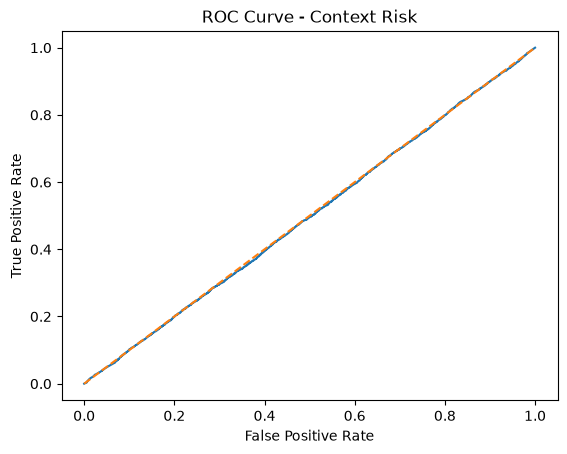

In [77]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(
    y_test,
    X_test_context["context_risk"]
)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Context Risk")
plt.show()

In [78]:
# Adding High Amount Risk - flag transactions whose amount is above the 95th percentile of the training data.
amount_threshold = X_train["TransactionAmt"].quantile(0.95)
X_test_context["high_amount_risk"] = (
    X_test_context["TransactionAmt"] >= amount_threshold
).astype(int)
print("Amount threshold:", amount_threshold)
print(X_test_context["high_amount_risk"].value_counts())

Amount threshold: 444.95
high_amount_risk
0    112131
1      5977
Name: count, dtype: int64


In [79]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(
    y_test,
    X_test_context["high_amount_risk"]
)
print("High Amount Risk ROC-AUC:", auc)

High Amount Risk ROC-AUC: 0.4981000360517721


In [80]:
print(
    X_test_context.assign(
        fraud=y_test.values
    ).groupby("high_amount_risk")["fraud"].mean()
)

high_amount_risk
0    0.035129
1    0.032458
Name: fraud, dtype: float64


In [81]:
#combining ML fraud probability and contextual signals
X_test_context["ml_risk"] = y_test_proba

X_test_context["cpde_risk_score"] = (
    0.7 * X_test_context["ml_risk"] +
    0.3 * X_test_context["context_risk"]
)

print(X_test_context[[
    "ml_risk",
    "context_risk",
    "cpde_risk_score"
]].head(10))

        ml_risk  context_risk  cpde_risk_score
243924     0.01      0.093088         0.034926
41973      0.03      0.118570         0.056571
51871      0.00      0.038717         0.011615
247681     0.02      0.028217         0.022465
239241     0.00      0.194336         0.058301
550798     0.21      0.097316         0.176195
37078      0.06      0.028217         0.050465
82808      0.00      0.382492         0.114748
111185     0.00      0.048873         0.014662
344616     0.00      0.122747         0.036824


In [82]:
from sklearn.metrics import roc_auc_score
cpde_auc = roc_auc_score(
    y_test,
    X_test_context["cpde_risk_score"]
)
print("CPDE Risk Score ROC-AUC:", cpde_auc)

CPDE Risk Score ROC-AUC: 0.9391977421920953


In [83]:
#finding the best ML/Context weighting

for ml_weight in [0.8, 0.85, 0.9, 0.95]:
    context_weight = 1 - ml_weight
    score = (
        ml_weight * X_test_context["ml_risk"]
        + context_weight * X_test_context["context_risk"]
    )
    auc = roc_auc_score(y_test, score)
    print(
        f"ML: {ml_weight:.2f}, "
        f"Context: {context_weight:.2f}, "
        f"ROC-AUC: {auc:.4f}"
    )

ML: 0.80, Context: 0.20, ROC-AUC: 0.9483
ML: 0.85, Context: 0.15, ROC-AUC: 0.9520
ML: 0.90, Context: 0.10, ROC-AUC: 0.9552
ML: 0.95, Context: 0.05, ROC-AUC: 0.9578


In [84]:
for feature in ["amount_deviation", "transaction_velocity", "high_amount_risk"]:
    auc = roc_auc_score(y_test, X_test_context[feature])
    print(f"{feature}: {auc:.4f}")

amount_deviation: 0.4961
transaction_velocity: 0.5040
high_amount_risk: 0.4981


In [85]:
context_features = [
    "amount_deviation",
    "transaction_velocity",
    "high_amount_risk"
]
X_test_with_context = X_test_rf.copy()
X_test_with_context[context_features] = X_test_context[context_features]
print(X_test_with_context.shape)

(118108, 26)


In [86]:
context_features = [
    "amount_deviation",
    "transaction_velocity",
    "high_amount_risk"
]
X_train_with_context = X_train[rf_model.feature_names_in_].copy()
X_train_with_context[context_features] = 0
print(X_train_with_context.shape)

(472432, 26)


In [87]:
#training a Random Forest with the 26 features

rf_context = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)
rf_context.fit(X_train_with_context, y_train)
y_context_proba = rf_context.predict_proba(X_test_with_context)[:, 1]
context_model_auc = roc_auc_score(
    y_test,
    y_context_proba
)
print("RF with Context ROC-AUC:", context_model_auc)

RF with Context ROC-AUC: 0.9611145023494153


In [88]:
context_importance = pd.Series(
    rf_context.feature_importances_,
    index=X_train_with_context.columns
).sort_values(ascending=False)
print(context_importance[
    ["amount_deviation", "transaction_velocity", "high_amount_risk"]
])

# Incorrect experiment:
# Context features were set to 0 for training, causing train/test mismatch.
# This model was discarded and is not used in the final CPDE.

amount_deviation        0.0
transaction_velocity    0.0
high_amount_risk        0.0
dtype: float64


In [89]:
del rf_context
del X_train_with_context

In [90]:
# Create contextual features for training data

amount_median_train = X_train.groupby("card1")["TransactionAmt"].median()

X_train_context = X_train[rf_model.feature_names_in_].copy()

X_train_context["normal_amount"] = (
    X_train_context["card1"].map(amount_median_train)
)

global_median_train = X_train["TransactionAmt"].median()

X_train_context["normal_amount"] = (
    X_train_context["normal_amount"].fillna(global_median_train)
)

X_train_context["amount_deviation"] = (
    abs(
        X_train_context["TransactionAmt"]
        - X_train_context["normal_amount"]
    )
    / (X_train_context["normal_amount"] + 1e-6)
)

amount_threshold_train = X_train["TransactionAmt"].quantile(0.95)

X_train_context["high_amount_risk"] = (
    X_train_context["TransactionAmt"] >= amount_threshold_train
).astype(int)

print(X_train_context.shape)
print(X_train_context[
    ["amount_deviation", "high_amount_risk"]
].head())

(472432, 26)
        amount_deviation  high_amount_risk
40809           0.636364                 0
285886          0.491264                 0
104256          0.169456                 0
507860          1.067949                 0
196382          1.018982                 0


In [91]:
import numpy as np

train_sorted = X_train[["card1", "TransactionDT"]].sort_values(
    ["card1", "TransactionDT"]
).copy()

def calculate_train_velocity(group):
    times = group["TransactionDT"].to_numpy()

    return pd.Series(
        np.searchsorted(times, times, side="left")
        - np.searchsorted(times, times - 86400, side="left"),
        index=group.index
    )

train_velocity = (
    train_sorted.groupby("card1", group_keys=False)
    .apply(calculate_train_velocity, include_groups=False)
)

X_train_context["transaction_velocity"] = (
    train_velocity.loc[X_train_context.index]
)

print(X_train_context["transaction_velocity"].describe())

count    472432.000000
mean         15.098048
std          36.772007
min           0.000000
25%           1.000000
50%           4.000000
75%          15.000000
max         697.000000
Name: transaction_velocity, dtype: float64


In [92]:
#creating the final 26-feature training matrix

context_features = [
    "amount_deviation",
    "transaction_velocity",
    "high_amount_risk"
]

X_train_final = X_train_context[
    rf_model.feature_names_in_.tolist() + context_features
]

X_test_final = X_test_context[
    rf_model.feature_names_in_.tolist() + context_features
]

print("Training shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)

Training shape: (472432, 26)
Test shape: (118108, 26)


In [93]:
#training the corrected Random Forest

rf_context = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_context.fit(X_train_final, y_train)

y_context_proba = rf_context.predict_proba(X_test_final)[:, 1]

context_model_auc = roc_auc_score(
    y_test,
    y_context_proba
)

print("RF with Context ROC-AUC:", context_model_auc)

RF with Context ROC-AUC: 0.4955782206961797


In [94]:
print("Train columns:")
print(X_train_final.columns.tolist())

print("\nTest columns:")
print(X_test_final.columns.tolist())

Train columns:
['TransactionAmt', 'TransactionDT', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'dist1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'amount_deviation', 'transaction_velocity', 'high_amount_risk']

Test columns:
['TransactionAmt', 'TransactionDT', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'dist1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'amount_deviation', 'transaction_velocity', 'high_amount_risk']


In [95]:
#comparing train vs test contextual features

print("TRAIN")
print(X_train_final[[
    "amount_deviation",
    "transaction_velocity",
    "high_amount_risk"
]].describe())

print("\nTEST")
print(X_test_final[[
    "amount_deviation",
    "transaction_velocity",
    "high_amount_risk"
]].describe())

TRAIN
       amount_deviation  transaction_velocity  high_amount_risk
count     472432.000000         472432.000000     472432.000000
mean           1.057114             15.098048          0.050035
std            2.553944             36.772007          0.218017
min            0.000000              0.000000          0.000000
25%            0.187821              1.000000          0.000000
50%            0.474576              4.000000          0.000000
75%            0.829661             15.000000          0.000000
max          292.138051            697.000000          1.000000

TEST
       amount_deviation  transaction_velocity  high_amount_risk
count     118108.000000         118108.000000     118108.000000
mean           1.094784             18.709063          0.050606
std            2.479079             45.649572          0.219193
min            0.000000              0.000000          0.000000
25%            0.220339              1.000000          0.000000
50%            0.492373     

In [96]:
print(
    X_train_context.groupby(y_train)[[
        "amount_deviation",
        "transaction_velocity",
        "high_amount_risk"
    ]].mean()
)

         amount_deviation  transaction_velocity  high_amount_risk
isFraud                                                          
0                1.049535             15.203030          0.049076
1                1.266138             12.202601          0.076467


In [97]:
#retraining the corrected Random Forest

rf_context = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_context.fit(X_train_final, y_train)

y_context_proba = rf_context.predict_proba(X_test_final)[:, 1]

context_model_auc = roc_auc_score(
    y_test,
    y_context_proba
)

print("RF with Context ROC-AUC:", context_model_auc)

RF with Context ROC-AUC: 0.4955782206961797


In [98]:
print("First 10 probabilities:")
print(y_context_proba[:10])

print("\nProbability range:")
print(y_context_proba.min(), y_context_proba.max())

print("\nMean probability - Legit:")
print(y_context_proba[y_test == 0].mean())

print("\nMean probability - Fraud:")
print(y_context_proba[y_test == 1].mean())

First 10 probabilities:
[0.15 0.   0.01 0.03 0.   0.02 0.06 0.07 0.03 0.05]

Probability range:
0.0 1.0

Mean probability - Legit:
0.053564729107260366

Mean probability - Fraud:
0.052973626905395595


In [99]:
#there was some deeper mismatch with the new rf model with 26 features so checking back to 23 features old rf model

In [100]:
print(rf_model)
print(rf_model.feature_names_in_.tolist())

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)
['TransactionAmt', 'TransactionDT', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'dist1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14']


In [101]:
y_original_proba = rf_model.predict_proba(X_test_rf)[:, 1]

original_auc = roc_auc_score(
    y_test,
    y_original_proba
)

print("Original RF ROC-AUC:", original_auc)

Original RF ROC-AUC: 0.9590823351252368


In [102]:
#time since the previous transaction for the same card

train_test_all = pd.concat([
    X_train[["card1", "TransactionDT"]],
    X_test[["card1", "TransactionDT"]]
]).sort_values(["card1", "TransactionDT"])

train_test_all["time_since_previous"] = (
    train_test_all
    .groupby("card1")["TransactionDT"]
    .diff()
)

X_test_context["time_since_previous"] = (
    train_test_all.loc[X_test_context.index, "time_since_previous"]
)

X_test_context["time_since_previous"] = (
    X_test_context["time_since_previous"].fillna(0)
)

print(X_test_context["time_since_previous"].describe())

count    1.181080e+05
mean     1.641921e+05
std      6.790590e+05
min      0.000000e+00
25%      8.440000e+02
50%      5.530500e+03
75%      5.582675e+04
max      1.545945e+07
Name: time_since_previous, dtype: float64


In [103]:
print(
    X_test_context.groupby(y_test)["time_since_previous"].mean()
)

isFraud
0    165744.724940
1    121374.405275
Name: time_since_previous, dtype: float64


In [104]:
time_gap_auc = roc_auc_score(
    y_test,
    -X_test_context["time_since_previous"]
)

print("Time-gap ROC-AUC:", time_gap_auc)

Time-gap ROC-AUC: 0.5008118394168201


In [105]:
#time-of-day / unusual transaction time
X_test_context["transaction_hour"] = (
    (X_test_context["TransactionDT"] // 3600) % 24
)

print(
    X_test_context.groupby(y_test)["transaction_hour"].mean()
)

isFraud
0    13.892433
1    13.187273
Name: transaction_hour, dtype: float64


In [106]:
hour_auc = roc_auc_score(
    y_test,
    X_test_context["transaction_hour"]
)

print("Transaction-hour ROC-AUC:", hour_auc)

Transaction-hour ROC-AUC: 0.5008028978555591


In [107]:
#transaction amount deviation in a slightly better way: instead of relative deviation from the card median,
#calculate the log-transformed transaction amount

X_test_context["log_amount"] = np.log1p(
    X_test_context["TransactionAmt"]
)

log_amount_auc = roc_auc_score(
    y_test,
    X_test_context["log_amount"]
)

print("Log-amount ROC-AUC:", log_amount_auc)

Log-amount ROC-AUC: 0.4989576213621371


In [108]:
#whether a transaction involving a card that has appeared only rarely in the training data behaves differently.

card_frequency = X_train["card1"].value_counts()

X_test_context["card_frequency"] = (
    X_test_context["card1"].map(card_frequency).fillna(0)
)

card_freq_auc = roc_auc_score(
    y_test,
    -X_test_context["card_frequency"]
)

print("Card-frequency ROC-AUC:", card_freq_auc)

Card-frequency ROC-AUC: 0.49848248097755554


In [109]:
#recipient/card identity consistency using card1 + addr1
identity_frequency = (
    X_train.groupby(["card1", "addr1"])
    .size()
)

test_identity = pd.MultiIndex.from_frame(
    X_test_context[["card1", "addr1"]]
)

X_test_context["identity_frequency"] = (
    identity_frequency.reindex(test_identity, fill_value=0).to_numpy()
)

identity_auc = roc_auc_score(
    y_test,
    -X_test_context["identity_frequency"]
)

print("Card-address frequency ROC-AUC:", identity_auc)

Card-address frequency ROC-AUC: 0.4948319866946511


In [110]:
#check whether the existing RF probability + ONE contextual feature improves performance
#transaction velocity

cpde_velocity_score = (
    0.9 * y_test_proba +
    0.1 * (
        X_test_context["transaction_velocity"] /
        X_test_context["transaction_velocity"].quantile(0.95)
    ).clip(0, 1)
)
velocity_cpde_auc = roc_auc_score(
    y_test,
    cpde_velocity_score
)
print("RF baseline ROC-AUC:", roc_auc_score(y_test, y_test_proba))
print("RF + velocity ROC-AUC:", velocity_cpde_auc)

RF baseline ROC-AUC: 0.9590823351252368
RF + velocity ROC-AUC: 0.9535650373066582


In [111]:
#next checking: amount deviation, combined with the RF
cpde_amount_score = (
    0.9 * y_test_proba +
    0.1 * (
        X_test_context["amount_deviation"] /
        X_test_context["amount_deviation"].quantile(0.95)
    ).clip(0, 1)
)

amount_cpde_auc = roc_auc_score(
    y_test,
    cpde_amount_score
)
print("RF baseline ROC-AUC:", roc_auc_score(y_test, y_test_proba))
print("RF + amount deviation ROC-AUC:", amount_cpde_auc)

RF baseline ROC-AUC: 0.9590823351252368
RF + amount deviation ROC-AUC: 0.9533938059839361


In [112]:
# next checking: high_amount_risk
cpde_high_amount_score = (
    0.9 * y_test_proba +
    0.1 * X_test_context["high_amount_risk"]
)
high_amount_cpde_auc = roc_auc_score(
    y_test,
    cpde_high_amount_score
)
print("RF baseline ROC-AUC:", roc_auc_score(y_test, y_test_proba))
print("RF + high amount risk ROC-AUC:", high_amount_cpde_auc)

RF baseline ROC-AUC: 0.9590823351252368
RF + high amount risk ROC-AUC: 0.9562604520551501


In [113]:
# ==========================================
# IEEE-CIS: Transaction + Identity Analysis
# ==========================================

In [114]:
import pandas as pd
identity_df = pd.read_csv("train_identity.csv")

In [115]:
identity_df.head(5)

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [116]:
identity_df.shape

(144233, 41)

In [117]:
identity_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144233 entries, 0 to 144232
Data columns (total 41 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionID  144233 non-null  int64  
 1   id_01          144233 non-null  float64
 2   id_02          140872 non-null  float64
 3   id_03          66324 non-null   float64
 4   id_04          66324 non-null   float64
 5   id_05          136865 non-null  float64
 6   id_06          136865 non-null  float64
 7   id_07          5155 non-null    float64
 8   id_08          5155 non-null    float64
 9   id_09          74926 non-null   float64
 10  id_10          74926 non-null   float64
 11  id_11          140978 non-null  float64
 12  id_12          144233 non-null  object 
 13  id_13          127320 non-null  float64
 14  id_14          80044 non-null   float64
 15  id_15          140985 non-null  object 
 16  id_16          129340 non-null  object 
 17  id_17          139369 non-nul

In [118]:
identity_df.isnull().sum()

TransactionID         0
id_01                 0
id_02              3361
id_03             77909
id_04             77909
id_05              7368
id_06              7368
id_07            139078
id_08            139078
id_09             69307
id_10             69307
id_11              3255
id_12                 0
id_13             16913
id_14             64189
id_15              3248
id_16             14893
id_17              4864
id_18             99120
id_19              4915
id_20              4972
id_21            139074
id_22            139064
id_23            139064
id_24            139486
id_25            139101
id_26            139070
id_27            139064
id_28              3255
id_29              3255
id_30             66668
id_31              3951
id_32             66647
id_33             70944
id_34             66428
id_35              3248
id_36              3248
id_37              3248
id_38              3248
DeviceType         3423
DeviceInfo        25567
dtype: int64

In [119]:
identity_df.duplicated().sum()

np.int64(0)

In [120]:
#checking how many Transaction IDs overlap
identity_df["TransactionID"].isin(
    df["TransactionID"]
).sum()

np.int64(144233)

In [121]:
identity_df["TransactionID"].nunique()

144233

In [122]:
identity_df["TransactionID"].nunique()

144233

In [123]:
#merge transaction + identity

merged_ieee_df = df.merge(
    identity_df,
    on="TransactionID",
    how="left"
)

In [124]:
merged_ieee_df.shape

(590540, 434)

In [125]:
merged_ieee_df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [126]:
merged_ieee_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float64(399), int64(4), object(31)
memory usage: 1.9+ GB


In [127]:
merged_ieee_df["id_01"].notnull().sum()

np.int64(144233)

In [128]:
merged_ieee_df["id_01"].isnull().sum()

np.int64(446307)

In [129]:
merged_ieee_df["isFraud"].value_counts()

isFraud
0    569877
1     20663
Name: count, dtype: int64

In [130]:
merged_ieee_df["isFraud"].value_counts(normalize=True)

isFraud
0    0.96501
1    0.03499
Name: proportion, dtype: float64

In [131]:
identity_df.isnull().mean().sort_values(ascending=False)

id_24            0.967088
id_25            0.964419
id_07            0.964259
id_08            0.964259
id_21            0.964231
id_26            0.964204
id_23            0.964162
id_27            0.964162
id_22            0.964162
id_18            0.687221
id_03            0.540161
id_04            0.540161
id_33            0.491871
id_09            0.480521
id_10            0.480521
id_30            0.462224
id_32            0.462079
id_34            0.460560
id_14            0.445037
DeviceInfo       0.177262
id_13            0.117262
id_16            0.103257
id_06            0.051084
id_05            0.051084
id_20            0.034472
id_19            0.034077
id_17            0.033723
id_31            0.027393
DeviceType       0.023732
id_02            0.023303
id_28            0.022568
id_29            0.022568
id_11            0.022568
id_15            0.022519
id_35            0.022519
id_36            0.022519
id_37            0.022519
id_38            0.022519
id_01       

In [132]:
identity_df.nunique().sort_values()

id_37                 2
id_35                 2
id_38                 2
id_29                 2
id_28                 2
id_27                 2
DeviceType            2
id_12                 2
id_36                 2
id_16                 2
id_23                 3
id_15                 3
id_34                 4
id_32                 4
id_24                12
id_04                15
id_18                18
id_03                24
id_22                25
id_14                25
id_09                46
id_13                54
id_10                62
id_30                75
id_01                77
id_07                84
id_05                93
id_08                94
id_26                95
id_06               101
id_17               104
id_31               130
id_33               260
id_25               341
id_11               365
id_20               394
id_21               490
id_19               522
DeviceInfo         1786
id_02            115655
TransactionID    144233
dtype: int64

In [133]:
identity_df.select_dtypes(include="object").nunique().sort_values(ascending=False)

DeviceInfo    1786
id_33          260
id_31          130
id_30           75
id_34            4
id_23            3
id_15            3
id_27            2
id_28            2
id_29            2
id_16            2
id_35            2
id_36            2
id_37            2
id_38            2
DeviceType       2
id_12            2
dtype: int64

In [134]:
identity_df["DeviceType"].value_counts(dropna=False)

DeviceType
desktop    85165
mobile     55645
NaN         3423
Name: count, dtype: int64

In [135]:
identity_df["id_12"].value_counts(dropna=False)

id_12
NotFound    123025
Found        21208
Name: count, dtype: int64

In [136]:
identity_df["id_15"].value_counts(dropna=False)

id_15
Found      67728
New        61612
Unknown    11645
NaN         3248
Name: count, dtype: int64

In [137]:
identity_features = [
    "id_01",
    "id_02",
    "id_05",
    "id_06",
    "id_11",
    "id_12",
    "id_13",
    "id_15",
    "id_16",
    "id_17",
    "id_19",
    "id_20",
    "id_28",
    "id_29",
    "id_31",
    "id_35",
    "id_36",
    "id_37",
    "id_38",
    "DeviceType"
]

In [138]:
merged_ieee_df.groupby("DeviceType")["isFraud"].mean()

DeviceType
desktop    0.065215
mobile     0.101662
Name: isFraud, dtype: float64

In [139]:
merged_ieee_df.groupby("id_12")["isFraud"].mean()

id_12
Found       0.059836
NotFound    0.081683
Name: isFraud, dtype: float64

In [140]:
merged_ieee_df.groupby("id_15")["isFraud"].mean()

id_15
Found      0.105097
New        0.049244
Unknown    0.091885
Name: isFraud, dtype: float64

In [141]:
#id_31

merged_ieee_df["id_31"].value_counts().head(20)

id_31
chrome 63.0                   22000
mobile safari 11.0            13423
mobile safari generic         11474
ie 11.0 for desktop            9030
safari generic                 8195
chrome 62.0                    7182
chrome 65.0                    6871
chrome 64.0                    6711
chrome 63.0 for android        5806
chrome generic                 4778
chrome 66.0                    4264
edge 16.0                      4188
chrome 64.0 for android        3473
chrome 65.0 for android        3336
firefox 57.0                   3315
mobile safari 10.0             2779
chrome 66.0 for android        2349
chrome 62.0 for android        2097
edge 15.0                      1600
chrome generic for android     1158
Name: count, dtype: int64

In [142]:
merged_ieee_df.groupby("id_31")["isFraud"].mean().sort_values(ascending=False).head(20)

id_31
Mozilla/Firefox            1.000000
icedragon                  1.000000
comodo                     0.666667
Lanix/Ilium                0.666667
chrome 49.0 for android    0.547170
opera                      0.481928
opera generic              0.448718
chrome 52.0 for android    0.381579
opera 49.0                 0.311594
samsung browser 5.4        0.302326
mobile                     0.272727
chrome 67.0                0.272727
chrome 58.0                0.271277
opera 51.0                 0.265306
chrome 43.0 for android    0.263889
chrome 50.0 for android    0.262069
samsung browser 5.2        0.243902
android webview 4.0        0.242105
chrome 55.0                0.234375
chrome 46.0 for android    0.231884
Name: isFraud, dtype: float64

In [143]:
#first Transaction + Identity RF experiment

identity_numeric_features = [
    "id_01",
    "id_02",
    "id_05",
    "id_06",
    "id_11",
    "id_13",
    "id_14",
    "id_17",
    "id_19",
    "id_20"
]

identity_categorical_features = [
    "id_12",
    "id_15",
    "id_16",
    "id_28",
    "id_29",
    "id_35",
    "id_36",
    "id_37",
    "id_38",
    "DeviceType"
]

In [144]:
transaction_features_identity = rf_model.feature_names_in_.tolist()

In [145]:
transaction_features_identity

['TransactionAmt',
 'TransactionDT',
 'card1',
 'card2',
 'card3',
 'card5',
 'addr1',
 'addr2',
 'dist1',
 'C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'C6',
 'C7',
 'C8',
 'C9',
 'C10',
 'C11',
 'C12',
 'C13',
 'C14']

In [146]:
# combined feature list

identity_features_all = (
    transaction_features_identity
    + identity_numeric_features
    + identity_categorical_features
)

In [147]:
len(identity_features_all)

43

In [148]:
#identity-enhanced dataframe
merged_identity_features = merged_ieee_df[identity_features_all].copy()

In [149]:
merged_identity_features.shape

(590540, 43)

In [150]:
merged_identity_features.head()

,TransactionAmt,TransactionDT,card1,card2,card3,card5,addr1,addr2,dist1,C1,...,id_12,id_15,id_16,id_28,id_29,id_35,id_36,id_37,id_38,DeviceType
0,68.5,86400,13926,NaN,150.0,142.0,315.0,87.0,19.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,29.0,86401,2755,404.0,150.0,102.0,325.0,87.0,NaN,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,59.0,86469,4663,490.0,150.0,166.0,330.0,87.0,287.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,50.0,86499,18132,567.0,150.0,117.0,476.0,87.0,NaN,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,50.0,86506,4497,514.0,150.0,102.0,420.0,87.0,NaN,1.0,...,NotFound,New,NotFound,New,NotFound,T,F,T,T,mobile


In [151]:
# checking missing values in selected 43 features
merged_identity_features.isnull().sum().sort_values(ascending=False)

id_14             510496
id_13             463220
id_16             461200
id_05             453675
id_06             453675
id_20             451279
id_19             451222
id_17             451171
DeviceType        449730
id_02             449668
id_28             449562
id_29             449562
id_11             449562
id_36             449555
id_38             449555
id_37             449555
id_15             449555
id_35             449555
id_12             446307
id_01             446307
dist1             352271
addr2              65706
addr1              65706
card2               8933
card5               4259
card3               1565
TransactionAmt         0
C14                    0
TransactionDT          0
C12                    0
C11                    0
C10                    0
C9                     0
C8                     0
C7                     0
C6                     0
C5                     0
C4                     0
C3                     0
C2                     0


In [152]:
#train-test-split

X_train_identity_raw = merged_identity_features.loc[X_train.index].copy()
X_test_identity_raw = merged_identity_features.loc[X_test.index].copy()

In [153]:
y_train_identity = y_train.copy()
y_test_identity = y_test.copy()

In [154]:
X_train_identity_raw.shape

(472432, 43)

In [155]:
X_test_identity_raw.shape

(118108, 43)

In [156]:
merged_identity_features.select_dtypes(include="object").columns

Index(['id_12', 'id_15', 'id_16', 'id_28', 'id_29', 'id_35', 'id_36', 'id_37',
       'id_38', 'DeviceType'],
      dtype='object')

In [157]:
merged_identity_features.select_dtypes(include="number").columns

Index(['TransactionAmt', 'TransactionDT', 'card1', 'card2', 'card3', 'card5',
       'addr1', 'addr2', 'dist1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7',
       'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'id_01', 'id_02',
       'id_05', 'id_06', 'id_11', 'id_13', 'id_14', 'id_17', 'id_19', 'id_20'],
      dtype='object')

In [158]:
#separating numerical and categorical data

identity_numeric_train = X_train_identity_raw[identity_numeric_features].copy()
identity_numeric_test = X_test_identity_raw[identity_numeric_features].copy()

identity_categorical_train = X_train_identity_raw[identity_categorical_features].copy()
identity_categorical_test = X_test_identity_raw[identity_categorical_features].copy()

In [159]:
#filling numerical missing values using training medians

identity_numeric_medians = identity_numeric_train.median()
identity_numeric_train = identity_numeric_train.fillna(identity_numeric_medians)
identity_numeric_test = identity_numeric_test.fillna(identity_numeric_medians)

In [160]:
#filling categorical missing values

identity_categorical_train = identity_categorical_train.fillna("Missing")
identity_categorical_test = identity_categorical_test.fillna("Missing")

In [161]:
numeric_features_identity = (
    transaction_features_identity
    + identity_numeric_features
)
identity_numeric_train = X_train_identity_raw[
    numeric_features_identity
].copy()

identity_numeric_test = X_test_identity_raw[
    numeric_features_identity
].copy()

In [162]:
identity_numeric_medians = identity_numeric_train.median()

In [163]:
identity_numeric_train = identity_numeric_train.fillna(
    identity_numeric_medians
)
identity_numeric_test = identity_numeric_test.fillna(
    identity_numeric_medians
)

In [164]:
identity_numeric_train.isnull().sum().sum()

np.int64(0)

In [165]:
identity_numeric_test.isnull().sum().sum()

np.int64(0)

In [166]:
#using OneHotEncoder on 10 categorical features

from sklearn.preprocessing import OneHotEncoder
identity_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [167]:
identity_categorical_train_encoded = identity_encoder.fit_transform(
    identity_categorical_train
)

In [168]:
identity_categorical_test_encoded = identity_encoder.transform(
    identity_categorical_test
)

In [169]:
identity_categorical_train_encoded.shape

(472432, 31)

In [170]:
identity_categorical_test_encoded.shape

(118108, 31)

In [171]:
#combining 
#33 numerical features
#      +
#31 one-hot identity features
#      ↓
#64-feature model input

X_train_identity_final = pd.concat(
    [
        identity_numeric_train.reset_index(drop=True),
        pd.DataFrame(
            identity_categorical_train_encoded,
            columns=identity_encoder.get_feature_names_out(
                identity_categorical_features
            )
        )
    ],
    axis=1
)
X_test_identity_final = pd.concat(
    [
        identity_numeric_test.reset_index(drop=True),
        pd.DataFrame(
            identity_categorical_test_encoded,
            columns=identity_encoder.get_feature_names_out(
                identity_categorical_features
            )
        )
    ],
    axis=1
)

In [172]:
X_train_identity_final.shape

(472432, 64)

In [173]:
X_test_identity_final.shape

(118108, 64)

In [174]:
#new Random Forest model

from sklearn.ensemble import RandomForestClassifier
rf_identity_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)
rf_identity_model.fit(
    X_train_identity_final,
    y_train_identity
)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [175]:
#evaluation of new model

y_identity_proba = rf_identity_model.predict_proba(
    X_test_identity_final
)[:, 1]

In [176]:
#roc value

from sklearn.metrics import roc_auc_score
roc_auc_identity = roc_auc_score(
    y_test_identity,
    y_identity_proba
)
roc_auc_identity

0.9628017730487608

adding the selected identity/device-related features improved ROC-AUC from 0.9591 → 0.9628, an absolute improvement of about 0.0037.

In [177]:
#classification report

from sklearn.metrics import classification_report
y_identity_pred = (
    y_identity_proba >= 0.5
).astype(int)
print(
    classification_report(
        y_test_identity,
        y_identity_pred
    )
)

              precision    recall  f1-score   support

           0       0.99      1.00      0.99    113975
           1       0.90      0.69      0.78      4133

    accuracy                           0.99    118108
   macro avg       0.94      0.84      0.89    118108
weighted avg       0.99      0.99      0.99    118108



In [178]:
#confusion matrix

from sklearn.metrics import confusion_matrix
confusion_matrix(
    y_test_identity,
    y_identity_pred
)

array([[113658,    317],
       [  1275,   2858]])

In [179]:
#feature importance

identity_feature_importance = pd.Series(
    rf_identity_model.feature_importances_,
    index=X_train_identity_final.columns
).sort_values(ascending=False)

In [180]:
identity_feature_importance.head(20)

TransactionDT     0.083847
TransactionAmt    0.078538
card1             0.073339
C13               0.068299
card2             0.062097
addr1             0.056204
C5                0.048772
C14               0.048049
C1                0.039173
C2                0.038374
card5             0.033496
C6                0.033339
dist1             0.032646
C11               0.025713
C8                0.024995
C9                0.023019
C4                0.021961
C10               0.020865
C12               0.015798
id_02             0.015141
dtype: float64

In [181]:
identity_feature_importance[
    identity_feature_importance.index.isin(
        identity_numeric_features + identity_categorical_features
    )
].sort_values(ascending=False)

id_02    0.015141
id_20    0.010725
id_19    0.010046
id_01    0.008500
id_17    0.008079
id_06    0.006493
id_05    0.006328
id_13    0.004911
id_14    0.002687
id_11    0.001061
dtype: float64

In [182]:
#total importance contributed by all identity features versus the original transaction features

transaction_importance_identity = identity_feature_importance[
    identity_feature_importance.index.isin(
        transaction_features_identity
    )
].sum()
identity_importance_total = identity_feature_importance[
    identity_feature_importance.index.isin(
        identity_numeric_features + identity_categorical_features
    )
].sum()
transaction_importance_identity, identity_importance_total

(np.float64(0.8520463843589547), np.float64(0.07397159758991093))

In [183]:
#calculating total identity importance

identity_importance_total = (
    identity_feature_importance[
        identity_feature_importance.index.isin(
            identity_numeric_features
        )
    ].sum()
    +
    identity_feature_importance[
        identity_feature_importance.index.str.startswith(
            tuple(identity_categorical_features)
        )
    ].sum()
)
identity_importance_total

np.float64(0.14795361564104514)

In [184]:
transaction_importance_identity = identity_feature_importance[
    identity_feature_importance.index.isin(
        transaction_features_identity
    )
].sum()
transaction_importance_identity

np.float64(0.8520463843589547)

In [185]:
#optimizing the new model's threshold

from sklearn.metrics import precision_recall_curve
precision_identity, recall_identity, thresholds_identity = precision_recall_curve(
    y_test_identity,
    y_identity_proba
)
f1_identity = (
    2 * precision_identity[:-1] * recall_identity[:-1]
    / (precision_identity[:-1] + recall_identity[:-1] + 1e-8)
)
best_identity_index = f1_identity.argmax()
best_identity_threshold = thresholds_identity[best_identity_index]
best_identity_precision = precision_identity[best_identity_index]
best_identity_recall = recall_identity[best_identity_index]
best_identity_f1 = f1_identity[best_identity_index]
best_identity_threshold, best_identity_precision, best_identity_recall, best_identity_f1

(np.float64(0.41),
 np.float64(0.8416140543508098),
 np.float64(0.7418340188724897),
 np.float64(0.7885802419334343))

In [186]:
#confusion matrix at 0.41

y_identity_pred_best = (
    y_identity_proba >= best_identity_threshold
).astype(int)
confusion_matrix(
    y_test_identity,
    y_identity_pred_best
)

array([[113398,    577],
       [  1067,   3066]])

In [187]:
import numpy as np

ieee_demo_transaction = X_test_rf.iloc[0].to_numpy(dtype=float)

np.save(
    "ieee_demo_transaction.npy",
    ieee_demo_transaction
)

print(ieee_demo_transaction.shape)

(23,)
